<a href="https://colab.research.google.com/github/RAHMAH099/nlp-project-group-rahmah-and-joanitah/blob/main/stanfordnlp_imdb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from datasets import load_dataset

df = load_dataset("stanfordnlp/imdb")
df

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})

In [2]:
train_full = df["train"].to_pandas()
test_full = df["test"].to_pandas()
print(train_full.shape, test_full.shape)
train_full.head(30)


(25000, 2) (25000, 2)


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0
5,I would put this at the top of my list of film...,0
6,Whoever wrote the screenplay for this movie ob...,0
7,"When I first saw a glimpse of this movie, I qu...",0
8,"Who are these ""They""- the actors? the filmmake...",0
9,This is said to be a personal film for Peter B...,0


In [3]:
# How many positive and negative reviews
print(train_full["label"].value_counts())

label
0    12500
1    12500
Name: count, dtype: int64


In [4]:
# Split each review by spaces and count the number of words
word_counts = train_full['text'].str.split().str.len()

# Calculate and print the average, shortest, and longest review lengths
print("Average review length:", int(word_counts.mean()), "words")
print("Shortest review:", word_counts.min(), "words")
print("Longest review:", word_counts.max(), "words")

Average review length: 233 words
Shortest review: 10 words
Longest review: 2470 words


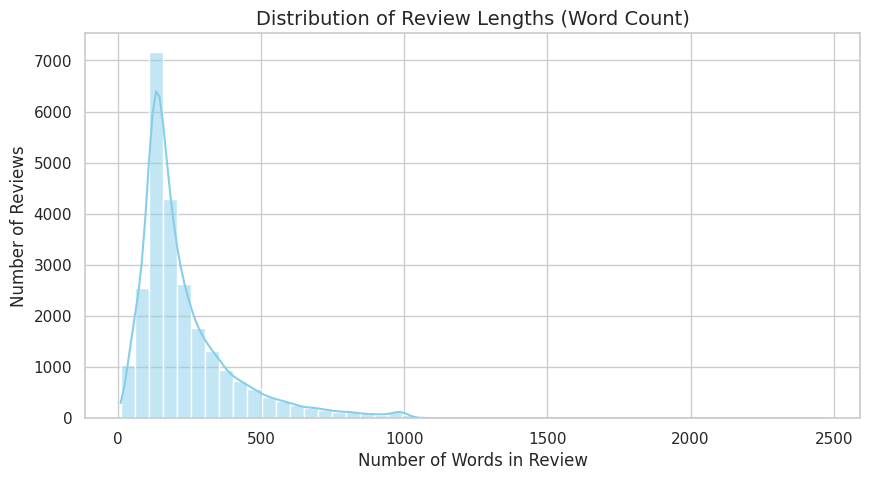

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")

# Create a histogram to visualize the distribution of review lengths
plt.figure(figsize=(10, 5))
sns.histplot(word_counts, bins=50, kde=True, color='skyblue')

# Add labels and a title
plt.title('Distribution of Review Lengths (Word Count)', fontsize=14)
plt.xlabel('Number of Words in Review', fontsize=12)
plt.ylabel('Number of Reviews', fontsize=12)

# Display the plot
plt.show()

In [6]:
# Take the first 3 reviews from the training dataset
examples = train_full.head(3)

# Loop through each review and print its index, label, and the text itself
for index, row in examples.iterrows():
    print(f"--- Review #{index + 1} ---")
    # Map numerical label to human-readable sentiment (0 = Negative, 1 = Positive)
    sentiment = "Positive" if row['label'] == 1 else "Negative"
    print(f"Sentiment: {sentiment}")
    print(f"Review Text:\n{row['text']}\n")

--- Review #1 ---
Sentiment: Negative
Review Text:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the

In [7]:
from sklearn.model_selection import train_test_split

# Split the train_full data into 80% training and 20% validation sets
# We set a random_state to make sure the split is reproducible
train_split, val_split = train_test_split(train_full, test_size=0.2, random_state=42)

# Display the sizes of the splits to confirm
print(f"Original training size: {len(train_full)}")
print(f"New training split size: {len(train_split)}")
print(f"Validation split size: {len(val_split)}")

Original training size: 25000
New training split size: 20000
Validation split size: 5000


In [8]:
# Convert text into numerical features
from sklearn.feature_extraction.text import TfidfVectorizer

# Import the Logistic Regression model
from sklearn.linear_model import LogisticRegression

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create the TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=20000)

# Learn from the training reviews
X_train_tfidf = tfidf.fit_transform(train_split["text"])

# Transform the validation reviews using the same vocabulary
X_val_tfidf = tfidf.transform(val_split["text"])

Here, converts movie reviews into numerical features that Logistic Regression can understand. fit_transform() learns the important word features from the training reviews, while transform() applies the same features to the validation reviews. This prevents the model from learning from validation data.


In [10]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Learn from the training reviews and their labels
model.fit(X_train_tfidf, train_split["label"])

LogisticRegression(max_iter=1000)

This cell creates and trains the Logistic Regression model. It learns patterns between the TF-IDF features and the sentiment labels, where 0 represents negative and 1 represents positive.

In [11]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Predict sentiment for validation reviews
y_pred = model.predict(X_val_tfidf)

# Get the actual validation labels
y_test = val_split["label"]

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Print classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

# Print confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8856

Classification Report:
              precision    recall  f1-score   support

    Negative       0.89      0.88      0.89      2515
    Positive       0.88      0.90      0.89      2485

    accuracy                           0.89      5000
   macro avg       0.89      0.89      0.89      5000
weighted avg       0.89      0.89      0.89      5000


Confusion Matrix:
[[2202  313]
 [ 259 2226]]


In this cell, we test the logistic regression model on the val set then evaluate the model depending on its metric scores.


Neural Networks


In [12]:
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, f1_score, classification_report

In [13]:
# Keras needs normal (dense) arrays, not sparse TF-IDF matrices
Xtr_nn = X_train_tfidf.toarray().astype("float32")
Xva_nn = X_val_tfidf.toarray().astype("float32")

# Labels from your split
y_train = train_split["label"].values
y_val = val_split["label"].values

# Sequential model (small capacity to prevent overfitting)
opt_nn_model = keras.Sequential([
    keras.Input(shape=(Xtr_nn.shape[1],)),
    layers.Dense(32, activation="relu", kernel_regularizer=regularizers.l2(0.005)),
    layers.Dropout(0.6),
    layers.Dense(1, activation="sigmoid")
])

opt_nn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Early stopping monitoring validation loss
early_stopping = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history = opt_nn_model.fit(
    Xtr_nn, y_train,
    validation_data=(Xva_nn, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stopping]
)

Epoch 1/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 12s 20ms/step - accuracy: 0.7125 - loss: 0.7000 - val_accuracy: 0.8306 - val_loss: 0.6665
Epoch 2/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.7838 - loss: 0.6590 - val_accuracy: 0.8340 - val_loss: 0.6462
Epoch 3/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.7928 - loss: 0.6428 - val_accuracy: 0.8412 - val_loss: 0.6284
Epoch 4/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8025 - loss: 0.6280 - val_accuracy: 0.8436 - val_loss: 0.6128
Epoch 5/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.8098 - loss: 0.6134 - val_accuracy: 0.8452 - val_loss: 0.5983
Epoch 6/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8156 - loss: 0.5998 - val_accuracy: 0.8524 - val_loss: 0.5848
Epoch 7/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8241 - loss: 0.5880 - val_accuracy: 0.8558 - val_loss: 0.5731
Epoch 8/30
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8316 - loss: 0.5770 - val_accuracy

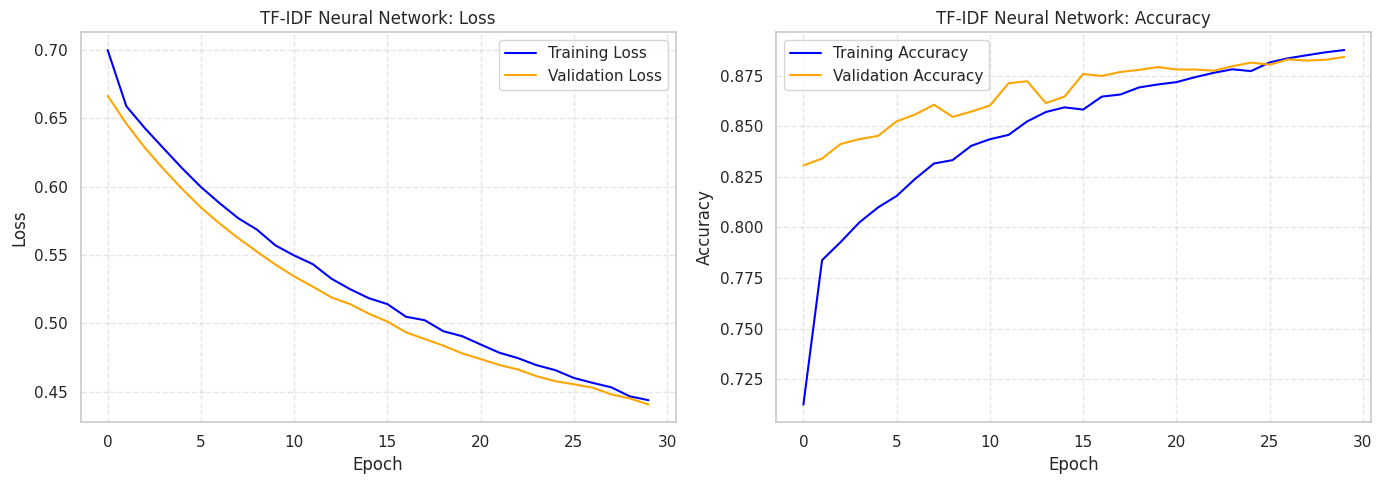

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
TF-IDF NN validation accuracy: 0.8842
TF-IDF NN validation F1: 0.8845002992220228
              precision    recall  f1-score   support

           0       0.89      0.88      0.88      2515
           1       0.88      0.89      0.88      2485

    accuracy                           0.88      5000
   macro avg       0.88      0.88      0.88      5000
weighted avg       0.88      0.88      0.88      5000



In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
axes[0].plot(history.history['loss'], label='Training Loss', color='blue')
axes[0].plot(history.history['val_loss'], label='Validation Loss', color='orange')
axes[0].set_title("TF-IDF Neural Network: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot Accuracy
axes[1].plot(history.history['accuracy'], label='Training Accuracy', color='blue')
axes[1].plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
axes[1].set_title("TF-IDF Neural Network: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Validation results
val_probs = opt_nn_model.predict(Xva_nn).ravel()
val_preds = (val_probs >= 0.5).astype(int)
print("TF-IDF NN validation accuracy:", accuracy_score(y_val, val_preds))
print("TF-IDF NN validation F1:", f1_score(y_val, val_preds))
print(classification_report(y_val, val_preds))

In [15]:
# 1. Text Vectorization (converts words to sequences of integer indices)
max_features = 10000   # vocabulary size
sequence_length = 250  # truncate/pad reviews to 250 words

vectorize_layer = layers.TextVectorization(
    max_tokens=max_features,
    output_mode='int',
    output_sequence_length=sequence_length
)

# Adapt on the training texts only
vectorize_layer.adapt(train_split["text"].values)

# Transform texts to integer sequences
Xtr_seq = vectorize_layer(train_split["text"].values)
Xva_seq = vectorize_layer(val_split["text"].values)

# 2. Neural network with an Embedding layer
embedding_dim = 16

emb_nn_model = keras.Sequential([
    keras.Input(shape=(sequence_length,)),
    layers.Embedding(input_dim=max_features, output_dim=embedding_dim, name="embedding"),
    layers.Dropout(0.2),
    layers.GlobalAveragePooling1D(),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

emb_nn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

emb_nn_model.summary()

# 3. Train with early stopping monitoring validation loss
emb_early_stopping = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=4,
    restore_best_weights=True,
    verbose=1
)

emb_history = emb_nn_model.fit(
    Xtr_seq, y_train,
    validation_data=(Xva_seq, y_val),
    epochs=25,
    batch_size=64,
    callbacks=[emb_early_stopping]
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 250, 16)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,289 (626.13 KB)

 Trainable params: 160,289 (626.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.6376 - loss: 0.6565 - val_accuracy: 0.7640 - val_loss: 0.5639
Epoch 2/25
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8137 - loss: 0.4549 - val_accuracy: 0.8398 - val_loss: 0.3754
Epoch 3/25
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8634 - loss: 0.3318 - val_accuracy: 0.8608 - val_loss: 0.3224
Epoch 4/25
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8859 - loss: 0.2815 - val_accuracy: 0.8748 - val_loss: 0.2999
Epoch 5/25
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9011 - loss: 0.2532 - val_accuracy: 0.8800 - val_loss: 0.2907
Epoch 6/25
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9133 - loss: 0.2269 - val_accuracy: 0.8780 - val_loss: 0.2891
Epoch 7/25
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9220 - loss: 0.2036 - val_accuracy: 0.8744 - val_loss: 0.3011
Epoch 8/25
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9275 - loss: 0.1915 - val_accuracy: 0

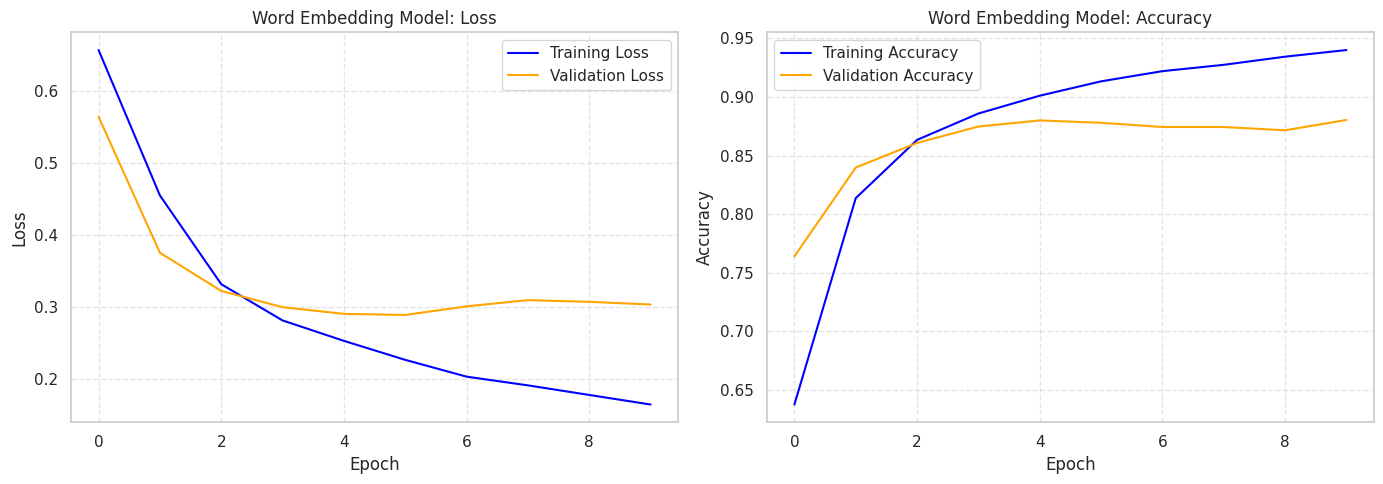

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Embedding NN validation accuracy: 0.878
Embedding NN validation F1: 0.8767676767676768
              precision    recall  f1-score   support

           0       0.88      0.88      0.88      2515
           1       0.88      0.87      0.88      2485

    accuracy                           0.88      5000
   macro avg       0.88      0.88      0.88      5000
weighted avg       0.88      0.88      0.88      5000



In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Loss
axes[0].plot(emb_history.history['loss'], label='Training Loss', color='blue')
axes[0].plot(emb_history.history['val_loss'], label='Validation Loss', color='orange')
axes[0].set_title("Word Embedding Model: Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot Accuracy
axes[1].plot(emb_history.history['accuracy'], label='Training Accuracy', color='blue')
axes[1].plot(emb_history.history['val_accuracy'], label='Validation Accuracy', color='orange')
axes[1].set_title("Word Embedding Model: Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Validation results
emb_probs = emb_nn_model.predict(Xva_seq).ravel()
emb_preds = (emb_probs >= 0.5).astype(int)
print("Embedding NN validation accuracy:", accuracy_score(y_val, emb_preds))
print("Embedding NN validation F1:", f1_score(y_val, emb_preds))
print(classification_report(y_val, emb_preds))

In [17]:
from sklearn.metrics import classification_report

# TF-IDF neural network
val_probs = opt_nn_model.predict(Xva_nn).ravel()
val_preds = (val_probs >= 0.5).astype(int)

print("=" * 55)
print("TF-IDF NEURAL NETWORK: Classification Report (validation)")
print("=" * 55)
print(classification_report(y_val, val_preds, digits=4))

# Word embedding neural network
emb_probs = emb_nn_model.predict(Xva_seq).ravel()
emb_preds = (emb_probs >= 0.5).astype(int)

print("=" * 55)
print("WORD EMBEDDING NEURAL NETWORK: Classification Report (validation)")
print("=" * 55)
print(classification_report(y_val, emb_preds, digits=4))

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
TF-IDF NEURAL NETWORK: Classification Report (validation)
              precision    recall  f1-score   support

           0     0.8916    0.8763    0.8839      2515
           1     0.8770    0.8922    0.8845      2485

    accuracy                         0.8842      5000
   macro avg     0.8843    0.8842    0.8842      5000
weighted avg     0.8843    0.8842    0.8842      5000

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
WORD EMBEDDING NEURAL NETWORK: Classification Report (validation)
              precision    recall  f1-score   support

           0     0.8757    0.8827    0.8792      2515
           1     0.8803    0.8732    0.8768      2485

    accuracy                         0.8780      5000
   macro avg     0.8780    0.8780    0.8780      5000
weighted avg     0.8780    0.8780    0.8780      5000



In [18]:
!pip install -q transformers accelerate

In [19]:
from transformers import AutoTokenizer
from datasets import Dataset

# Load the DistilBERT tokenizer
tokenizer = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")

# Convert data into Hugging Face datasets
train_data = Dataset.from_pandas(train_split[["text", "label"]].reset_index(drop=True))
val_data = Dataset.from_pandas(val_split[["text", "label"]].reset_index(drop=True))

# Tokenize the reviews
def tokenize_reviews(data):
    return tokenizer(data["text"], truncation=True, max_length=256)

train_data = train_data.map(tokenize_reviews, batched=True)
val_data = val_data.map(tokenize_reviews, batched=True)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

The tokenizer converts each review into numerical tokens DistilBERT can understand. It prepares both datasets without changing your original data.

In [20]:
from transformers import AutoModelForSequenceClassification

# Load DistilBERT for sentiment classification
model_bert = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased",
    num_labels=2
)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading the DistilBERT model with a classification layer for two sentiment categories: negative and positive. The model has not learned your dataset's sentiment patterns yet. That happens during training.

In [21]:
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding

# Automatically pad reviews to equal lengths in each batch
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# Set the training settings
training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=2,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch",
    report_to="none"
)

# Prepare the trainer
trainer = Trainer(
    model=model_bert,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=val_data,
    data_collator=data_collator
)

Configuring the training process. It specifies the model, datasets, batch sizes, number of training epochs, and evaluation settings.

In [22]:
trainer.train()

Epoch,Training Loss,Validation Loss
1,0.287826,0.311818
2,0.168989,0.346654


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=5000, training_loss=0.2635406448364258, metrics={'train_runtime': 1171.4348, 'train_samples_per_second': 34.146, 'train_steps_per_second': 4.268, 'total_flos': 2646085963428096.0, 'train_loss': 0.2635406448364258, 'epoch': 2.0})

In [23]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import numpy as np

# Get predictions from the validation reviews
results = trainer.predict(val_data)

# Convert model scores into predicted labels
y_pred_bert = np.argmax(results.predictions, axis=1)

# Get the actual validation labels
y_true_bert = val_data["label"]

# Calculate accuracy
print("Accuracy:", accuracy_score(y_true_bert, y_pred_bert))

# Display classification report
print("\nClassification Report:")
print(classification_report(
    y_true_bert,
    y_pred_bert,
    target_names=["Negative", "Positive"]
))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_true_bert, y_pred_bert))

Accuracy: 0.9108

Classification Report:
              precision    recall  f1-score   support

    Negative       0.91      0.91      0.91      2515
    Positive       0.91      0.91      0.91      2485

    accuracy                           0.91      5000
   macro avg       0.91      0.91      0.91      5000
weighted avg       0.91      0.91      0.91      5000


Confusion Matrix:
[[2289  226]
 [ 220 2265]]


Evaluating the DistilBERT model performance.

In [32]:
test_sub = test_full.loc[y_test.index]
test_texts = test_sub["text"].astype(str)

# TF-IDF neural network (uses your fitted tfidf)
Xte_nn = tfidf.transform(test_texts).toarray().astype("float32")
tfidf_nn_pred = (opt_nn_model.predict(Xte_nn).ravel() >= 0.5).astype(int)

# Word embedding neural network (uses your fitted vectorize_layer)
Xte_seq = vectorize_layer(test_texts.values)
emb_nn_pred = (emb_nn_model.predict(Xte_seq).ravel() >= 0.5).astype(int)

# All four numbers should be 5000
print(len(test_texts), len(y_test), len(tfidf_nn_pred), len(emb_nn_pred))

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
5000 5000 5000 5000


In [33]:
import pandas as pd
# Compare Logistic Regression, DistilBERT and the Neural Networks
results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "DistilBERT",
        "Neural Network (TF-IDF)",
        "Neural Network (Word Embedding)"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_true_bert, y_pred_bert),
        accuracy_score(y_test, tfidf_nn_pred),
        accuracy_score(y_test, emb_nn_pred)
    ],
    "Macro F1": [
        classification_report(y_test, y_pred, output_dict=True)["macro avg"]["f1-score"],
        classification_report(y_true_bert, y_pred_bert, output_dict=True)["macro avg"]["f1-score"],
        classification_report(y_test, tfidf_nn_pred, output_dict=True)["macro avg"]["f1-score"],
        classification_report(y_test, emb_nn_pred, output_dict=True)["macro avg"]["f1-score"]
    ]
})

results_df

,Model,Accuracy,Macro F1
0,Logistic Regression,0.8856,0.885597
1,DistilBERT,0.9108,0.910798
2,Neural Network (TF-IDF),0.8724,0.872400
3,Neural Network (Word Embedding),0.8602,0.860152


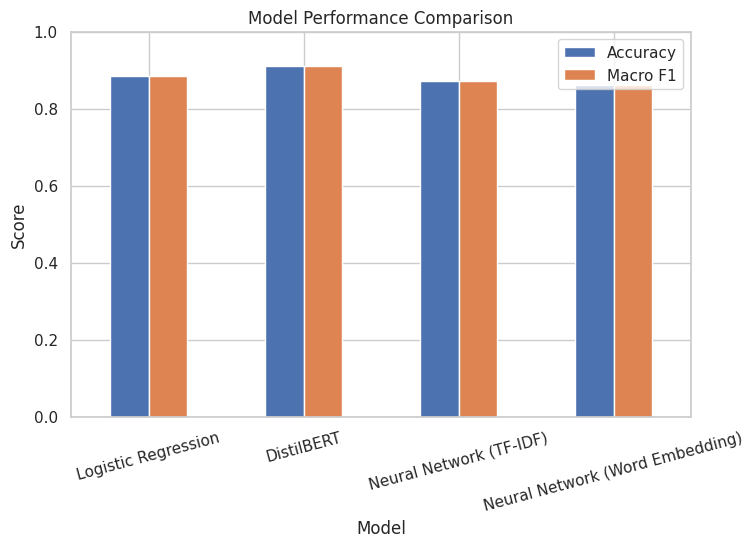

In [34]:
import matplotlib.pyplot as plt

# Plot accuracy and Macro F1 for both models
results_df.plot(
    x="Model",
    y=["Accuracy", "Macro F1"],
    kind="bar",
    figsize=(8, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend()
plt.show()

In [35]:
# Save the trained model using its name
trainer.save_model("./model_bert")

# Save the tokenizer using the same folder
tokenizer.save_pretrained("./model_bert")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('./model_bert/tokenizer_config.json', './model_bert/tokenizer.json')

In [36]:
from google.colab import drive
drive.mount('/content/drive')

trainer.save_model('/content/drive/MyDrive/model_bert')
tokenizer.save_pretrained('/content/drive/MyDrive/model_bert')

Mounted at /content/drive


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/model_bert/tokenizer_config.json',
 '/content/drive/MyDrive/model_bert/tokenizer.json')

In [37]:
import torch

def predict_sentiment(review):
    # Convert the review into tokens
    inputs = tokenizer(
        review,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=256
    )

    # Move inputs to the model's device (GPU or CPU)
    inputs = {key: value.to(model_bert.device) for key, value in inputs.items()}

    # Make a prediction without calculating gradients
    with torch.no_grad():
        outputs = model_bert(**inputs)

    # Get the predicted class
    prediction = outputs.logits.argmax(dim=1).item()

    # Return the sentiment
    if prediction == 1:
        return "Positive"
    else:
        return "Negative"

Function to help predict for a given review.

In [38]:
review = input("Enter a movie review: ")

sentiment = predict_sentiment(review)

print("Predicted Sentiment:", sentiment)

Enter a movie review: this is good.
Predicted Sentiment: Positive
